In [7]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import classification_report
import shap
import matplotlib.pyplot as plt

              precision    recall  f1-score   support

       False       1.00      1.00      1.00        14
        True       1.00      1.00      1.00        27

    accuracy                           1.00        41
   macro avg       1.00      1.00      1.00        41
weighted avg       1.00      1.00      1.00        41



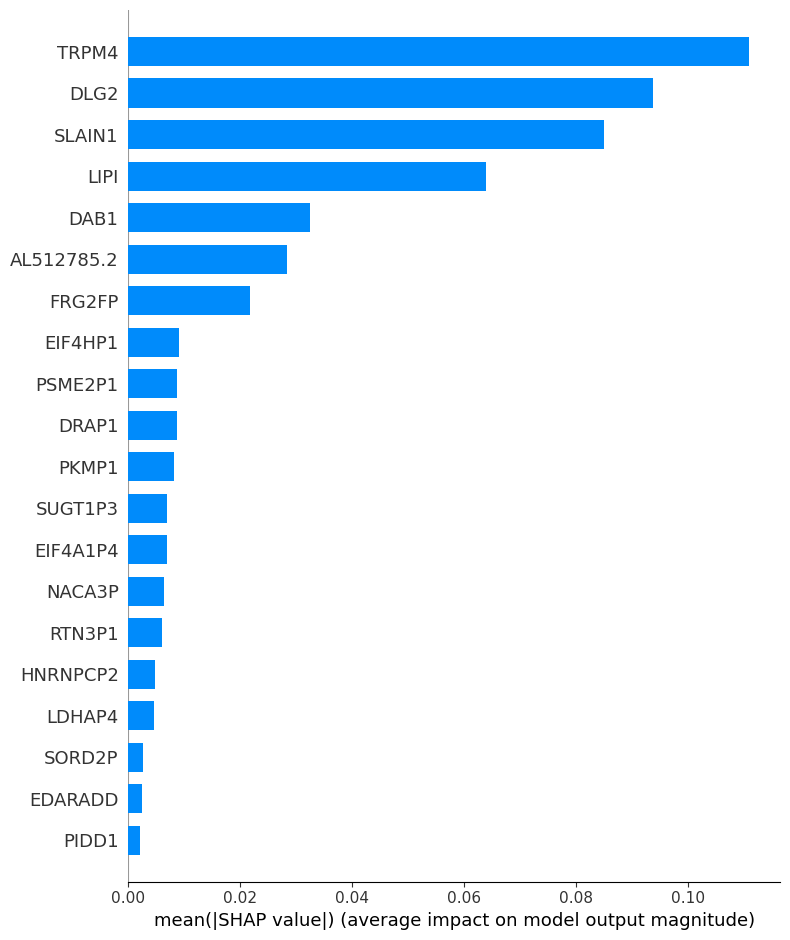

In [8]:
# Load data
df = pd.read_csv("data_for_RF.csv")
X = df.drop(columns=["EWS", "cell_line"])
y = df["EWS"]

# LOOCV - justified by small N
loo = LeaveOneOut()
rf = RandomForestClassifier(n_estimators=500, random_state=42, class_weight="balanced")
# class_weight="balanced" handles your 27 vs 14 imbalance

y_pred = cross_val_predict(rf, X, y, cv=loo)
print(classification_report(y, y_pred))

# Fit on full data for SHAP
rf.fit(X, y)

# SHAP
explainer = shap.TreeExplainer(rf)
explanation = explainer(X)

shap_values = explanation.values
# for binary classification this is 3D: (samples, features, classes)
# take class 1 (Ewing = True)
shap.summary_plot(shap_values[:, :, 1], X, plot_type="bar", max_display=20)

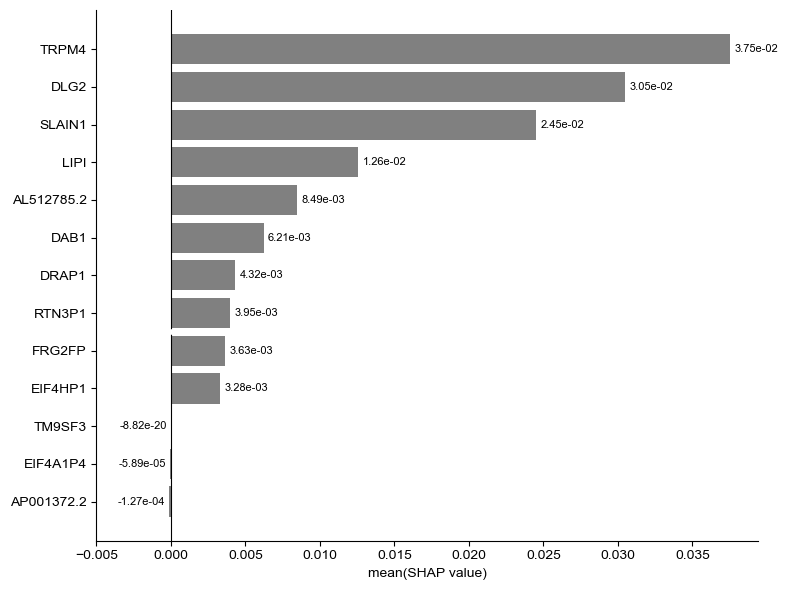

In [9]:
import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

mean_shap = shap_values[:, :, 1].mean(axis=0)

shap_df = pd.DataFrame({
    'feature': X.columns,
    'mean_shap': mean_shap
})

top_pos = shap_df.nlargest(10, 'mean_shap')
top_neg = shap_df.nsmallest(3, 'mean_shap')

plot_df = pd.concat([top_neg, top_pos]).sort_values('mean_shap', ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(plot_df)), plot_df['mean_shap'], color='grey')
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df['feature'])
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('mean(SHAP value)')
ax.axhline(y=4.5, color='white', linewidth=4)

# values on top
for i, (val, name) in enumerate(zip(plot_df['mean_shap'], plot_df['feature'])):
    offset = 0.0003 if val >= 0 else -0.0003
    ha = 'left' if val >= 0 else 'right'
    ax.text(val + offset, i, f'{val:.2e}', va='center', ha=ha, fontsize=8)

sns.despine(ax=ax, left=False, bottom=False)

ax.set_xlim(left=-0.005)

plt.tight_layout()
plt.savefig("shap_plot.pdf", bbox_inches='tight', dpi=300)

In [13]:
shap_df.to_csv("shap_values.csv", index=False)

In [11]:
top_pos

,feature,mean_shap
10,TRPM4,0.037545
8,DLG2,0.030471
5,SLAIN1,0.024520
6,LIPI,0.012577
1,AL512785.2,0.008489
7,DAB1,0.006214
21,DRAP1,0.004318
33,RTN3P1,0.003952
0,FRG2FP,0.003625
30,EIF4HP1,0.003277
